# Flux-Augmented Graph-Native RL — End-to-End Walkthrough

Bu notebook, Orbit Wars için inşa ettiğimiz **flux-augmented credit-assignment**
pipeline'ını baştan sona, gerçek tensörler üzerinden gezinerek anlatıyor.
Pipeline üç faz halinde tasarlandı:

| Faz | Ne yapar | Kullanılan dosya |
|---|---|---|
| **Foundation** | `Observation`'a fleet routing array'leri (`fleet_src_slot`, `fleet_tgt_slot`, `fleet_eta_raw`, `fleet_ships_raw`, `fleet_is_self`, `fleet_is_enemy`) | `obs_builder.py` |
| **Flux Helpers** | `compute_flux_matrices` + `compute_node_flux_features` (modes: `raw`/`linear`/`exp_decay`, tau parametrik) | `rl/flux.py` |
| **Phase 1 — Reward** | `_graph_node_metrics` 8 → 12 kanal, `graph_native` reward'da γφ(s')−φ(s) potential-based shaping üzerinden flux delta'sı | `model_graph_pyg.py`, `rl/rewards.py` |
| **Phase 3 — Encoder** | `PygPlanetGraphEncoder` / `PygEdgeNativePolicy` ctor'larında `enable_flux_features=True` ile node input 42 → 46 | `model_graph_pyg.py`, `model_graph_pyg_edgeonly.py` |
| **Phase 2 — Sinkhorn** | `SinkhornEdgeHead`: log-domain row/col `logsumexp` iterasyonları → multi-launch koordinasyonu için yaklaşık doubly-stochastic edge logits | `model_graph_pyg.py`, `model_graph_pyg_edgeonly.py` |

### Akış (yüksek seviye)

```
                          ┌────────────────────────────────────┐
env step ───► raw obs ───►│  build_observation(...)            │──► Observation
                          │  + fleet routing arrays            │     (planet_feats, fleet_feats,
                          └────────────────────────────────────┘      fleet_src_slot, ...)
                                            │
                                            ▼
                          ┌────────────────────────────────────┐
                          │  compute_node_flux_features(obs)   │──► (P_max, 4)
                          │   - raw / linear / exp_decay       │     [friendly_in/out, enemy_in/out]
                          └────────────────────────────────────┘
                                            │
                                            ├─► reward path: graph_metrics_summary (8 or 12 ch)
                                            │     → γφ(s')−φ(s) potential-based shaping
                                            │
                                            └─► encoder input: _graph_node_metrics + flux
                                                  → PygPlanetGraphEncoder (46-dim input)
                                                  → Policy: src/edge logits, value
                                                  → action (src, tgt, ship_value)
```

## 1. Ortam ve import'lar

Tüm import'lar buradan; aşağıdaki hücreler bu modülleri kullanır.

In [2]:
import logging
logging.disable(logging.CRITICAL)  # silence kaggle_environments noise

import os
import sys
# Notebook lives under docs/, but the source modules sit at the workspace
# root.  Bolt that onto sys.path so the imports below resolve.
_workspace_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if _workspace_root not in sys.path:
    sys.path.insert(0, _workspace_root)

import math
import numpy as np
import torch
import matplotlib.pyplot as plt

# Project modules
from kaggle_environments import make
from obs_builder import (
    build_observation, decode_action_with_launch,
    EDGE_FEATURE_DIM, FLEET_FEATURE_DIM, GLOBAL_FEATURE_DIM,
    P_MAX_DEFAULT, PLANET_FEATURE_DIM,
)
from feature_extraction import parse_planets, parse_fleets
from navigation import compute_launch

from rl.flux import (
    compute_flux_matrices, compute_node_flux_features,
    DEFAULT_FLUX_MODE, DEFAULT_TAU, DEFAULT_ETA_NORM, DEFAULT_SHIP_NORM,
    NODE_FLUX_CHANNELS,
)
from rl.rewards import (
    RewardConfig, build_reward_config,
    compute_graph_metrics_summary, compute_graph_native_reward,
)
from rl.buffer import RolloutBuffer, Transition
from rl.ppo import PPOConfig, ppo_update
from rl.rollout import collect_episode
from rl.train import _make_policy

from model_graph_pyg import (
    GRAPH_NODE_METRIC_DIM, GRAPH_NODE_FLUX_DIM, GRAPH_NODE_METRIC_DIM_FLUX,
    PYG_PLANET_FEATURE_DIM, PYG_PLANET_FEATURE_DIM_FLUX, PYG_EDGE_FEATURE_DIM,
    SinkhornEdgeHead,
    observation_to_pyg_data, packed_observations_to_pyg_batch,
    _graph_node_metrics, _estimated_intercept_eta_matrix,
)

torch.manual_seed(0)
np.random.seed(0)

print(f"PLANET_FEATURE_DIM           = {PLANET_FEATURE_DIM}")
print(f"GRAPH_NODE_METRIC_DIM        = {GRAPH_NODE_METRIC_DIM}  (base graph metrics per node)")
print(f"GRAPH_NODE_FLUX_DIM          = {GRAPH_NODE_FLUX_DIM}   (flux channels added by rl.flux)")
print(f"GRAPH_NODE_METRIC_DIM_FLUX   = {GRAPH_NODE_METRIC_DIM_FLUX}  (base + flux)")
print(f"PYG_PLANET_FEATURE_DIM       = {PYG_PLANET_FEATURE_DIM}  (encoder input, no flux)")
print(f"PYG_PLANET_FEATURE_DIM_FLUX  = {PYG_PLANET_FEATURE_DIM_FLUX}  (encoder input, with flux)")
print(f"PYG_EDGE_FEATURE_DIM         = {PYG_EDGE_FEATURE_DIM}")

Loading environment cabt failed: dlopen(/Users/doruksarigun/Kaggle/orbit-wars/orbit_wars_env/lib/python3.14/site-packages/kaggle_environments/envs/cabt/cg/libcg.so, 0x0006): tried: '/Users/doruksarigun/Kaggle/orbit-wars/orbit_wars_env/lib/python3.14/site-packages/kaggle_environments/envs/cabt/cg/libcg.so' (slice is not valid mach-o file), '/System/Volumes/Preboot/Cryptexes/OS/Users/doruksarigun/Kaggle/orbit-wars/orbit_wars_env/lib/python3.14/site-packages/kaggle_environments/envs/cabt/cg/libcg.so' (no such file), '/Users/doruksarigun/Kaggle/orbit-wars/orbit_wars_env/lib/python3.14/site-packages/kaggle_environments/envs/cabt/cg/libcg.so' (slice is not valid mach-o file)
PLANET_FEATURE_DIM           = 34
GRAPH_NODE_METRIC_DIM        = 8  (base graph metrics per node)
GRAPH_NODE_FLUX_DIM          = 4   (flux channels added by rl.flux)
GRAPH_NODE_METRIC_DIM_FLUX   = 12  (base + flux)
PYG_PLANET_FEATURE_DIM       = 42  (encoder input, no flux)
PYG_PLANET_FEATURE_DIM_FLUX  = 46  (encoder inp

## 2. Çevre ve `Observation`

Orbit Wars env'i açıyoruz, birkaç step ilerletip gerçek bir observation alıyoruz.
Sonra `build_observation` ile bunu policy'nin yiyebileceği yapıya çeviriyoruz.

`Observation` artık, flux hesabı için gerekli **fleet routing array'lerini**
(`fleet_src_slot`, `fleet_tgt_slot`, `fleet_eta_raw`, `fleet_ships_raw`,
`fleet_is_self`, `fleet_is_enemy`) tutar.  Bu alanlar default `-1`/`0`'dır;
sadece bir uçuş başlattığımızda dolarlar.

In [3]:
env = make("orbit_wars", debug=False)
env.configuration["randomSeed"] = 42
state = env.reset(num_agents=2)
state = env.step([[] for _ in range(2)])  # env initialises planets here
av = float(state[0].observation.get("angular_velocity", 0.0) or 0.0)

# Force a launch so we have at least one in-flight fleet to play with.
planets = state[0].observation["planets"]
mine = [p for p in planets if int(p[1]) == 0]
others = [p for p in planets if int(p[1]) != 0]
parsed = parse_planets(state[0].observation)
chosen_launch = None
for cand_src in mine:
    for cand_tgt in others:
        sp = next((p for p in parsed if p.id == int(cand_src[0])), None)
        tp = next((p for p in parsed if p.id == int(cand_tgt[0])), None)
        if sp is None or tp is None:
            continue
        cand = compute_launch(sp, tp, max(1, int(cand_src[5]) // 2), parsed, av)
        if cand is not None:
            chosen_launch = (cand_src, cand_tgt, cand)
            break
    if chosen_launch is not None:
        break

assert chosen_launch is not None, "no reachable target in this seed"
src, tgt, launch = chosen_launch
a0 = [[int(src[0]), float(launch["angle"]), int(launch["ships"])]]
state = env.step([a0, []])

# Step a few extra turns so the fleet has a non-zero ETA in our snapshot.
for _ in range(3):
    state = env.step([[], []])

obs = build_observation(state[0].observation, player=0, angular_velocity=av)
print(f"planet_feats : {obs.planet_feats.shape}   (P_max, PLANET_FEATURE_DIM)")
print(f"fleet_feats  : {obs.fleet_feats.shape}    (F_max, FLEET_FEATURE_DIM)")
print(f"edge_bias    : {obs.edge_bias.shape}      (P_max, P_max, EDGE_FEATURE_DIM)")
print(f"planet_mask  : {obs.planet_mask.shape}    real planets: {int(obs.planet_mask.sum())}")
print(f"fleet_mask   : {obs.fleet_mask.shape}     active fleets: {int(obs.fleet_mask.sum())}")

planet_feats : (44, 34)   (P_max, PLANET_FEATURE_DIM)
fleet_feats  : (64, 11)    (F_max, FLEET_FEATURE_DIM)
edge_bias    : (109, 109, 6)      (P_max, P_max, EDGE_FEATURE_DIM)
planet_mask  : (44,)    real planets: 36
fleet_mask   : (64,)     active fleets: 1


### 2.1 Fleet routing — `Observation`'a eklenen yeni alanlar

Bu altı dizi (her biri uzunlukta `F_max`) flux hesabını besler:

- `fleet_src_slot[k]`: filo `k`'nın geldiği gezegenin **slot index'i** (yoksa `-1`)
- `fleet_tgt_slot[k]`: ETA-predicted hedef slot
- `fleet_eta_raw[k]`: kalan tur (ham scalar, normalize edilmemiş)
- `fleet_ships_raw[k]`: filodaki gemi sayısı
- `fleet_is_self[k]`, `fleet_is_enemy[k]`: sahiplik bayrakları (neutral planetler bunların ikisinde de False)

Boş slot'lar (`fleet_mask[k] == False`) her zaman güvenli default'ta kalır.

In [4]:
active = obs.fleet_mask
active_idx = np.where(active)[0]
print(f"Active fleet slots: {active_idx.tolist()}")

# Pretty-print just the active fleets
print(f"\n{'slot':>4} {'src':>4} {'tgt':>4} {'eta':>7} {'ships':>6} {'self':>5} {'enemy':>5}")
print("-" * 42)
for k in active_idx:
    print(f"{k:>4} {obs.fleet_src_slot[k]:>4} {obs.fleet_tgt_slot[k]:>4} "
          f"{obs.fleet_eta_raw[k]:>7.2f} {obs.fleet_ships_raw[k]:>6.1f} "
          f"{str(bool(obs.fleet_is_self[k])):>5} {str(bool(obs.fleet_is_enemy[k])):>5}")

Active fleet slots: [0]

slot  src  tgt     eta  ships  self enemy
------------------------------------------
   0    4    1   22.00    5.0  True False


## 3. Flux: in-flight fleet flow'unu reward-friendly çevirmek

`rl/flux.py` modülü iki helper sunar:

1. **`compute_flux_matrices(obs, mode, tau, eta_norm)`** → `FluxMatrices(friendly, enemy)`,
   her biri `(P_max, P_max)`.  Hücre `M[i, j]` = `i → j` yönündeki **ağırlıklı**
   gemi akışı.
2. **`compute_node_flux_features(obs, ...)`** → `(P_max, 4)`:
   `[friendly_in, friendly_out, enemy_in, enemy_out]`.  Column-sum
   (`axis=0`) inbound, row-sum (`axis=1`) outbound.

**Üç parametrik mod**:

| Mode | Per-fleet weight | Yorum |
|---|---|---|
| `raw` | `ships` | filo gemilerinin toplamı; ETA önemsiz |
| `linear` | `ships * max(0, 1 - eta/eta_norm)` | yakın gelecekteki varışlar üstün |
| `exp_decay` | `ships * exp(-eta / tau)` | yumuşak, varış yakınlığına göre yumuşak ağırlık |

Aşağıda üç modun **ağırlık eğrisini** çiziyoruz.

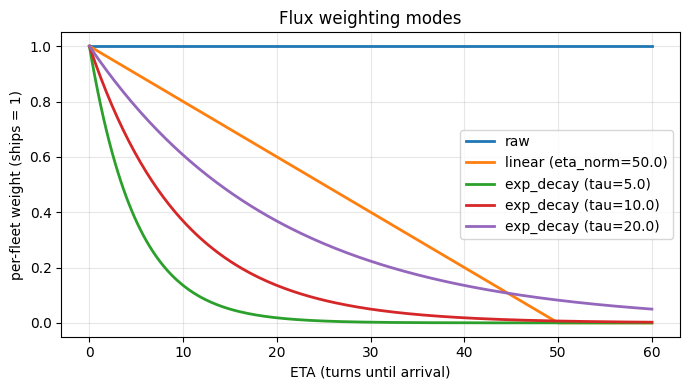

In [5]:
etas = np.linspace(0, 60, 200)
ships = 1.0
plt.figure(figsize=(7, 4))
plt.plot(etas, np.ones_like(etas) * ships, label='raw', lw=2)
plt.plot(etas, np.maximum(0.0, 1.0 - etas / DEFAULT_ETA_NORM) * ships,
         label=f'linear (eta_norm={DEFAULT_ETA_NORM})', lw=2)
for tau in (5.0, DEFAULT_TAU, 20.0):
    plt.plot(etas, np.exp(-etas / tau) * ships, label=f'exp_decay (tau={tau})', lw=2)
plt.xlabel('ETA (turns until arrival)')
plt.ylabel('per-fleet weight (ships = 1)')
plt.title('Flux weighting modes')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3.1 Gerçek `obs` üzerinde flux matrisleri

Şimdi yukarıdaki adımda `state` üzerinden alıp pakettiğimiz observasyondaki
filolar üzerinde matrisleri hesaplayalım.  Bizim oyuncumuza ait (`self`) ve
düşmana ait (`enemy`) matrisleri ayrı ayrı veriyoruz.

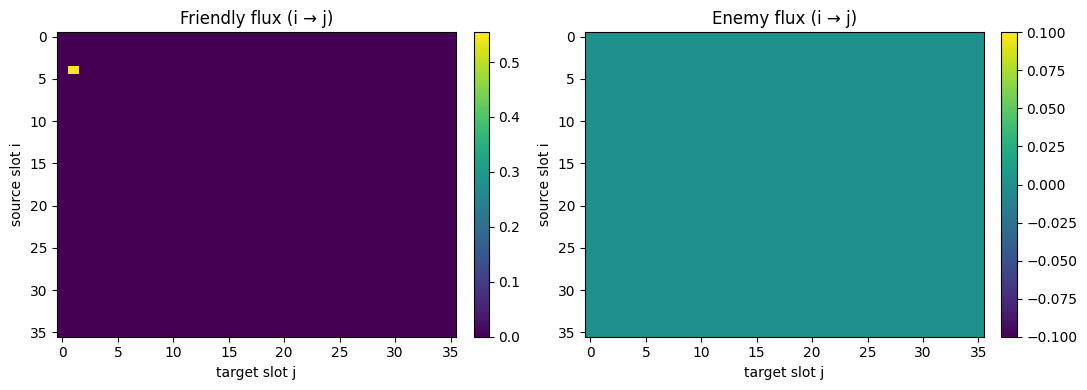

friendly total weighted ships in flight: 0.554
enemy    total weighted ships in flight: 0.000


In [6]:
matrices = compute_flux_matrices(obs, mode="exp_decay", tau=DEFAULT_TAU)
n_real = int(obs.planet_mask.sum())

# Crop to real planets only for clearer plots.
fr = matrices.friendly[:n_real, :n_real]
en = matrices.enemy[:n_real, :n_real]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, mat, title in [(axes[0], fr, 'Friendly flux (i → j)'),
                       (axes[1], en, 'Enemy flux (i → j)')]:
    im = ax.imshow(mat, cmap='viridis', aspect='auto')
    ax.set_title(title)
    ax.set_xlabel('target slot j')
    ax.set_ylabel('source slot i')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()
print(f"friendly total weighted ships in flight: {fr.sum():.3f}")
print(f"enemy    total weighted ships in flight: {en.sum():.3f}")

### 3.2 Node-level flux features

`compute_node_flux_features` yukarıdaki matrisleri *node başına* 4 kanala daraltır:

- `[:, 0]` = `friendly_in`  → column-sum of `friendly` matrix
- `[:, 1]` = `friendly_out` → row-sum of `friendly` matrix
- `[:, 2]` = `enemy_in`     → column-sum of `enemy` matrix
- `[:, 3]` = `enemy_out`    → row-sum of `enemy` matrix

Tüm değerler `ship_norm` (default 50.0) ile bölünür ki diğer graph metricleriyle
aynı büyüklük aralığında olsunlar.  Padded planet slot'ları sıfır kalır.

flux_feat.shape = (44, 4)


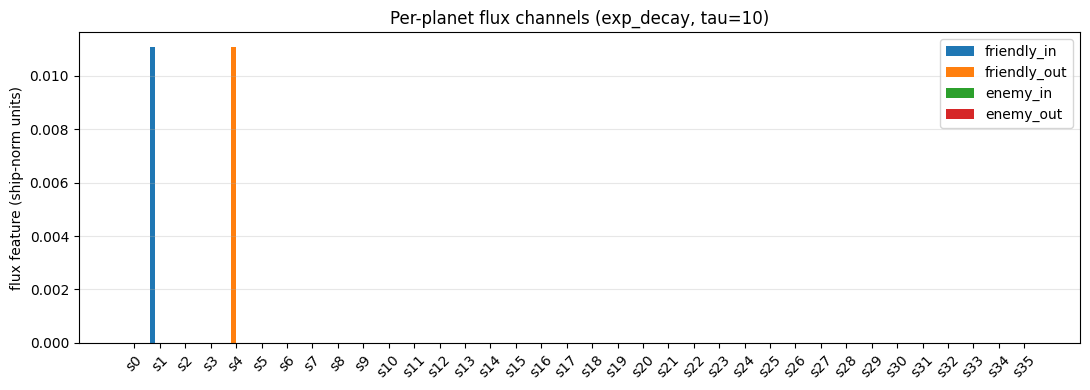

In [7]:
flux_feat = compute_node_flux_features(obs, mode="exp_decay", tau=DEFAULT_TAU)
print(f"flux_feat.shape = {flux_feat.shape}")

# Plot bar chart for the first n_real planets.
labels = [f's{i}' for i in range(n_real)]
x = np.arange(n_real)
width = 0.2
plt.figure(figsize=(11, 4))
plt.bar(x - 1.5 * width, flux_feat[:n_real, 0], width, label='friendly_in')
plt.bar(x - 0.5 * width, flux_feat[:n_real, 1], width, label='friendly_out')
plt.bar(x + 0.5 * width, flux_feat[:n_real, 2], width, label='enemy_in')
plt.bar(x + 1.5 * width, flux_feat[:n_real, 3], width, label='enemy_out')
plt.xticks(x, labels, rotation=45)
plt.ylabel('flux feature (ship-norm units)')
plt.title('Per-planet flux channels (exp_decay, tau=10)')
plt.legend()
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

## 4. Graph metrics — 8 baz + 4 flux = 12 kanal

`_graph_node_metrics(planet_feats, edge_bias, num_nodes, *, flux_features=None)`
gezegen başına aşağıdaki **base 8 kanalı** üretir:

0. `friendly_influence`
1. `enemy_influence`
2. `influence_balance` (redundant: friendly − enemy)
3. `friendly_support` (kernel'in diagonal'ı sıfırlanmış halinin friendly görüntü)
4. `supportability` (clamp(friendly_support / (enemy_influence + 1), 0, 10) / 10)
5. `vulnerability`  (clamp(enemy_influence / (ships + 1), 0, 10) / 10)
6. `production_potential`
7. `strategic_potential` (redundant: production + friendly − enemy)

`flux_features` (shape `(num_nodes, 4)`) verilirse, dönüş 12 kanal:
**`[base 8 ..., friendly_in, friendly_out, enemy_in, enemy_out]`**.

base node metrics: (36, 8)
flux-augmented:    (36, 12)


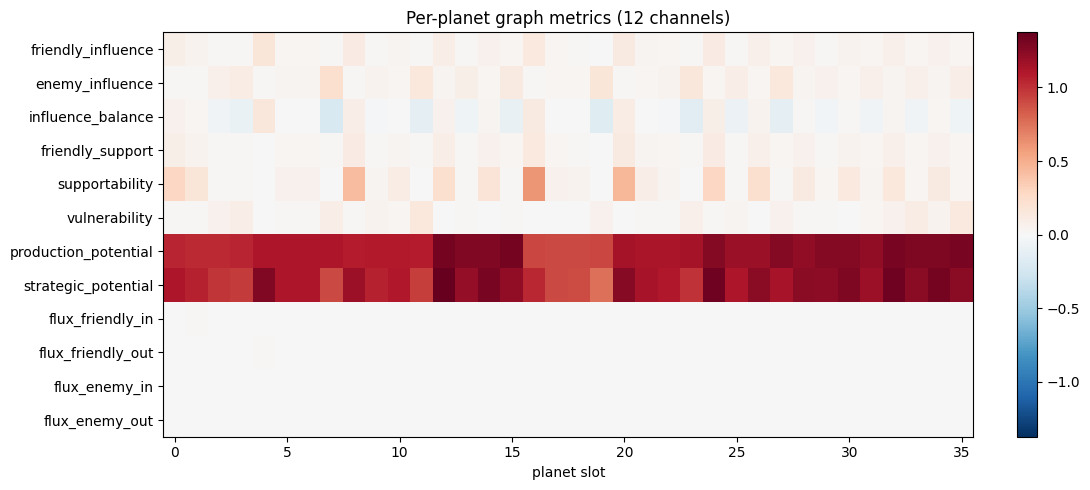

In [8]:
planet_feats = torch.from_numpy(obs.planet_feats).float()
edge_bias = torch.from_numpy(obs.edge_bias).float()
eta_mat = _estimated_intercept_eta_matrix(planet_feats, edge_bias, n_real)

# Without flux: 8 channels
base8 = _graph_node_metrics(planet_feats, edge_bias, n_real, eta=eta_mat)
print(f"base node metrics: {tuple(base8.shape)}")

# With flux: 12 channels
flux_t = torch.from_numpy(flux_feat[:n_real]).float()
metrics12 = _graph_node_metrics(planet_feats, edge_bias, n_real, eta=eta_mat,
                                 flux_features=flux_t)
print(f"flux-augmented:    {tuple(metrics12.shape)}")

channel_names = [
    'friendly_influence', 'enemy_influence', 'influence_balance',
    'friendly_support', 'supportability', 'vulnerability',
    'production_potential', 'strategic_potential',
    'flux_friendly_in', 'flux_friendly_out', 'flux_enemy_in', 'flux_enemy_out',
]
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(metrics12.numpy().T, aspect='auto', cmap='RdBu_r',
               vmin=-metrics12.abs().max().item(), vmax=metrics12.abs().max().item())
ax.set_yticks(range(len(channel_names)))
ax.set_yticklabels(channel_names)
ax.set_xlabel('planet slot')
ax.set_title('Per-planet graph metrics (12 channels)')
plt.colorbar(im, ax=ax, fraction=0.025)
plt.tight_layout()
plt.show()

## 5. `graph_native` reward — potential-based shaping

Yer çekimi gibi bir formül: φ(s) = Σᵢ wᵢ · sum-over-planets(channel_i).
Bir adımda reward:

$$
r_t = \gamma \cdot \varphi(s_{t+1}) - \varphi(s_t),
\qquad \gamma = \text{graph\_potential\_discount} \approx 0.99
$$

Ng, Harada & Russell (1999) gereği bu **potential-based shaping** optimal
policy'yi değiştirmez ama dense bir öğrenme sinyali sağlar.

`compute_graph_metrics_summary(obs, cfg=...)` her node metrik kanalının
**toplamını** (ve seçili bir edge kanalının toplamını) döner.  `cfg`'de
`enable_flux_metrics=True` ise 12 kanal, yoksa 8.

Aşağıda iki kontrolü gösteriyoruz:
1. **Tarafsız test** — ön/sonraki obs aynı → reward yalnız γ-discount kayması (ufak)
2. **Asimetri testi** — "sahte" boş obs (filo yok) ve gerçek obs (filolar var) farkı → flux ağırlıkları aktif olduğunda gerçek bir delta

In [9]:
# Two-channel demo: same obs forward
cfg_off = RewardConfig(enable_flux_metrics=False)
cfg_on = RewardConfig(
    enable_flux_metrics=True,
    graph_flux_friendly_in_weight=0.5,
    graph_flux_friendly_out_weight=0.25,
    graph_flux_enemy_in_weight=-0.5,
    graph_flux_enemy_out_weight=-0.25,
    graph_potential_discount=0.99,
    reward_scale=1.0,            # raw, no scaling
    graph_reward_normalize=False,
)

summary_off = compute_graph_metrics_summary(obs, cfg=cfg_off)
summary_on  = compute_graph_metrics_summary(obs, cfg=cfg_on)
print(f"summary_off['node_sum']  channels: {len(summary_off['node_sum'])}")
print(f"summary_on ['node_sum']  channels: {len(summary_on['node_sum'])}  (last 4 are flux)")
print(f"flux summed values: {[round(v, 4) for v in summary_on['node_sum'][8:]]}")

summary_off['node_sum']  channels: 8
summary_on ['node_sum']  channels: 12  (last 4 are flux)
flux summed values: [0.0111, 0.0111, 0.0, 0.0]


**Şimdi** sahte bir "no-fleet" obs ile karşılaştıralım.  Beklenen davranış:
ön (filo yok) → şimdi (filolar var) geçişinde `friendly_in/out` ↑ ve dolayısıyla
pozitif ağırlıklarla reward > 0; flux kapalıyken aynı geçiş tüm 8 baz kanalda
ufak değişikliklerden ibaret.

In [10]:
from dataclasses import replace
# "Empty fleets" snapshot — sadece filoları sıfırla, planetler aynı
empty_obs = replace(
    obs,
    fleet_feats=np.zeros_like(obs.fleet_feats),
    fleet_mask=np.zeros_like(obs.fleet_mask),
    fleet_src_slot=np.full_like(obs.fleet_src_slot, -1),
    fleet_tgt_slot=np.full_like(obs.fleet_tgt_slot, -1),
    fleet_eta_raw=np.zeros_like(obs.fleet_eta_raw),
    fleet_ships_raw=np.zeros_like(obs.fleet_ships_raw),
    fleet_is_self=np.zeros_like(obs.fleet_is_self),
    fleet_is_enemy=np.zeros_like(obs.fleet_is_enemy),
)

prev_summary_on = compute_graph_metrics_summary(empty_obs, cfg=cfg_on)
curr_summary_on = summary_on

r_no_weights = compute_graph_native_reward(
    prev_summary_on, curr_summary_on, player=0,
    cfg=replace(cfg_on,
                graph_flux_friendly_in_weight=0.0,
                graph_flux_friendly_out_weight=0.0,
                graph_flux_enemy_in_weight=0.0,
                graph_flux_enemy_out_weight=0.0),
    turn=4,
)
r_with_weights = compute_graph_native_reward(
    prev_summary_on, curr_summary_on, player=0, cfg=cfg_on, turn=4,
)
print(f"r (flux weights = 0):  {r_no_weights:.6f}")
print(f"r (flux weights set):  {r_with_weights:.6f}")
print(f"==> only the second one credits the in-flight friendly fleet.")

r (flux weights = 0):  0.000000
r (flux weights set):  0.008161
==> only the second one credits the in-flight friendly fleet.


## 6. PyG Encoder + Policy — Phase 3 (flux features encoder'a)

Iki yardımcı:
- `observation_to_pyg_data(obs, *, flux_features=None)`:
  tek bir gözlemi `torch_geometric.data.Data`'ya çevirir.  `flux_features` verilirse
  `Data.x`'in son boyutu **42 → 46** olur.
- `packed_observations_to_pyg_batch(batch, flux_features=None)`:
  pack_observations çıkışını (`B`-batch) tek bir `Batch`'e çevirir.

Encoder ve policy konstruktörlerinde `enable_flux_features=True` flag'i
node projection katmanının in-features'ını 46'ya genişletir.

In [11]:
# 1) Without flux: 42 columns
data_off = observation_to_pyg_data(obs)
print(f"Data.x without flux : {tuple(data_off.x.shape)}")

# 2) With flux: 46 columns
flux_tensor = torch.from_numpy(flux_feat).float()  # (P_max, 4) — sliced by observation_to_pyg_data
data_on = observation_to_pyg_data(obs, flux_features=flux_tensor)
print(f"Data.x with flux    : {tuple(data_on.x.shape)}")
print(f"Edge attr (15 dim) : {tuple(data_on.edge_attr.shape)}")
print(f"Edge index         : {tuple(data_on.edge_index.shape)}  (2 x num_edges)")

ImportError: model_graph_pyg requires torch_geometric. Install a torch-compatible PyTorch Geometric build before using PygPlanetGraphPolicy.

### 6.1 Policy forward — `PygPlanetGraphPolicy(enable_flux_features=True)`

`_make_policy('pyg_planet_graph', enable_flux_features=True, ...)` ile inşa edip
sentetik bir batch geçiriyoruz.  Forward, eksik `flux_features` argümanı verilirse
**loud** olarak `ValueError` fırlatır (sessiz sıfır broadcast yapmaz — bug masking
önlemi).

In [ ]:
pol = _make_policy(
    'pyg_planet_graph',
    d_model=64, n_heads=4, n_layers=2,
    attention_type='full', n_inducing_points=32,
    enable_flux_features=True,
)
print(f"policy variant       = {pol.model_variant}")
print(f"enable_flux_features = {pol.enable_flux_features}")
print(f"encoder_planet_dim   = {pol.encoder_planet_dim}")
print(f"params               = {sum(p.numel() for p in pol.parameters()):,}")

# Forward pass with the real obs
from model import pack_observations
B = 1
batch_dict = pack_observations([obs])
batch_dict["flux_features"] = torch.from_numpy(flux_feat).float().unsqueeze(0)  # (1, P_max, 4)
out = pol(**batch_dict)
print(f"\nForward output shapes:")
print(f"  src_logits  : {tuple(out.src_logits.shape)}")
print(f"  tgt_logits  : {tuple(out.tgt_logits.shape)}")
print(f"  ship_params : {tuple(out.ship_params.shape)}")
print(f"  value       : {tuple(out.value.shape)}")

policy variant       = pyg_planet_graph
enable_flux_features = True
encoder_planet_dim   = 46
params               = 98,145

Forward output shapes:
  src_logits  : (1, 45)
  tgt_logits  : (1, 44, 44)
  ship_params : (1, 44, 44, 2)
  value       : (1,)


## 7. `SinkhornEdgeHead` — Phase 2

Multi-launch koordinasyonu için **log-domain** Sinkhorn iterasyonları:

```
L_0 = raw / tau
L_{k+1} = L_k − logsumexp(L_k, dim=2, keepdim=True)   # row-normalize
        ← (yeniden ata)
        − logsumexp(L_k, dim=1, keepdim=True)         # col-normalize
```

`K` iterasyon sonrası `exp(L_K)` yaklaşık **doubly-stochastic**: her satır
toplam 1, her sütun toplam 1.  Bu, "bir kaynak tüm hedefleri ezsin" davranışını
zorlaştırır ve transport-plan benzeri yumuşak bir dağılım üretir.

Edge mask desteklenir: invalid hücreler (self-loop, padded planet, non-source)
−∞'a sürülür ve iterasyon onları görmezden gelir.

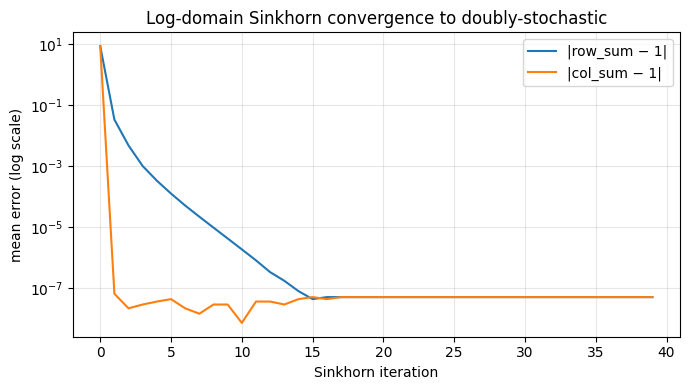

In [ ]:
# Visualize convergence: random log-scores → doubly-stochastic
torch.manual_seed(7)
P = 8
raw = torch.randn(1, P, P)

# Mask self-loops
mask = torch.ones(1, P, P, dtype=torch.bool)
mask[:, torch.eye(P, dtype=torch.bool)] = False

# Track per-iteration row/col sum errors.
err_rows, err_cols = [], []
L = raw.clone()
very_neg = torch.finfo(L.dtype).min
L = L.masked_fill(~mask, very_neg)
for k in range(40):
    plan_k = L.exp()
    row_err = (plan_k.sum(dim=2) - 1.0).abs().mean().item()
    col_err = (plan_k.sum(dim=1) - 1.0).abs().mean().item()
    err_rows.append(row_err)
    err_cols.append(col_err)
    L = L - torch.logsumexp(L, dim=2, keepdim=True)
    L = L - torch.logsumexp(L, dim=1, keepdim=True)

plt.figure(figsize=(7, 4))
plt.semilogy(err_rows, label='|row_sum − 1|')
plt.semilogy(err_cols, label='|col_sum − 1|')
plt.xlabel('Sinkhorn iteration')
plt.ylabel('mean error (log scale)')
plt.title('Log-domain Sinkhorn convergence to doubly-stochastic')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

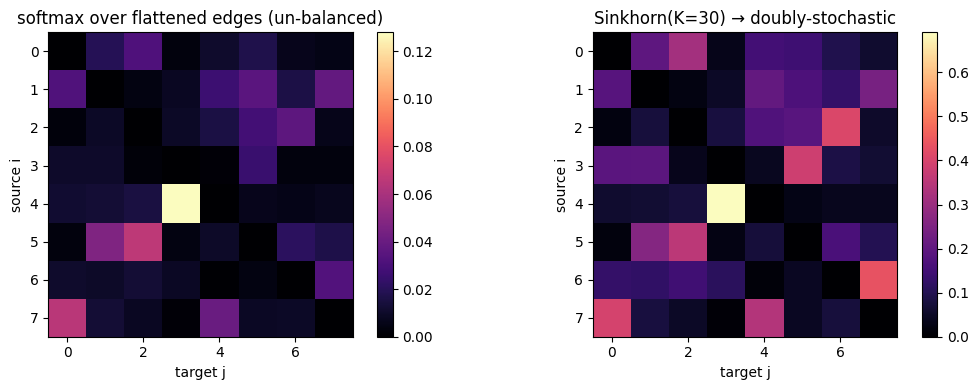

row sums (Sinkhorn): [1.         0.99999994 1.         1.         0.99999976 1.
 1.         1.0000001 ]
col sums (Sinkhorn): [0.99999994 0.99999994 0.99999994 1.         0.99999994 0.9999999
 1.         0.99999994]


In [ ]:
# Side-by-side: raw scores → exp(raw) (un-normalized) vs Sinkhorn plan
L_init = (raw.clone()).masked_fill(~mask, very_neg)
plan_init = torch.softmax(L_init.reshape(1, -1), dim=-1).reshape(1, P, P)  # uniform across all valid cells

L_sinkhorn = SinkhornEdgeHead.sinkhorn_log(raw.clone(), num_iterations=30, edge_mask=mask)
plan_sk = L_sinkhorn.exp()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, m, ttl in [(axes[0], plan_init[0], 'softmax over flattened edges (un-balanced)'),
                   (axes[1], plan_sk[0], 'Sinkhorn(K=30) → doubly-stochastic')]:
    im = ax.imshow(m.numpy(), cmap='magma')
    ax.set_title(ttl)
    plt.colorbar(im, ax=ax, fraction=0.046)
    ax.set_xlabel('target j'); ax.set_ylabel('source i')
plt.tight_layout()
plt.show()
print(f"row sums (Sinkhorn): {plan_sk[0].sum(dim=1).numpy()}")
print(f"col sums (Sinkhorn): {plan_sk[0].sum(dim=0).numpy()}")

### 7.1 `PygEdgeNativePolicy` ile end-to-end

Sinkhorn'u policy'ye opt-in olarak takıyoruz:

In [ ]:
edge_pol = _make_policy(
    'pyg_edge_native',
    d_model=64, n_heads=4, n_layers=2,
    attention_type='full', n_inducing_points=32,
    enable_flux_features=True,
    enable_sinkhorn=True, sinkhorn_iters=5, sinkhorn_tau=0.7,
)
print(f"edge-native variant   = {edge_pol.model_variant}")
print(f"enable_flux_features  = {edge_pol.enable_flux_features}")
print(f"enable_sinkhorn       = {edge_pol.enable_sinkhorn}")
print(f"sinkhorn_iters / tau  = {edge_pol.sinkhorn_iters} / {edge_pol.sinkhorn_tau}")
print(f"params                = {sum(p.numel() for p in edge_pol.parameters()):,}")

batch_dict = pack_observations([obs])
batch_dict["flux_features"] = torch.from_numpy(flux_feat).float().unsqueeze(0)
with torch.no_grad():
    edge_out = edge_pol(**batch_dict)
print(f"\nedge-native out shapes:")
print(f"  src_logits  : {tuple(edge_out.src_logits.shape)}")
print(f"  tgt_logits  : {tuple(edge_out.tgt_logits.shape)}")  # (B, P, P)

edge-native variant   = pyg_edge_native
enable_flux_features  = True
enable_sinkhorn       = True
sinkhorn_iters / tau  = 5 / 0.7
params                = 85,728

edge-native out shapes:
  src_logits  : (1, 45)
  tgt_logits  : (1, 44, 44)


## 8. End-to-end: rollout + buffer + PPO

`collect_episode`, policy'nin `enable_flux_features=True` olduğunu görürse:
1. Action-zamanı `_pack_with_flux` ile her `policy(...)` çağrısında
   `compute_node_flux_features(...)` hesabını batch'e iliştirir.
2. Her `Transition`'a kaydedilen `flux_features` numpy array'i `(P_max, 4)`.
3. PPO update'inde `buffer._stack` bu alanları `(B, P_max, 4)` olarak
   minibatch'e koyar; `rl/ppo.py` `policy.forward(..., flux_features=...)` ile
   geçirir.

In [ ]:
cfg = build_reward_config('graph_native')
# Override: reward-side flux'i de aç (aksi takdirde encoder flux kullanılır
# ama reward 8-channel kalır).
from dataclasses import replace as dc_replace
cfg = dc_replace(cfg,
    enable_flux_metrics=True,
    graph_flux_friendly_in_weight=0.5, graph_flux_friendly_out_weight=0.25,
    graph_flux_enemy_in_weight=-0.5, graph_flux_enemy_out_weight=-0.25,
)
print(f"reward_system        = {cfg.reward_system}")
print(f"enable_flux_metrics  = {cfg.enable_flux_metrics}")
print(f"flux_mode/tau        = {cfg.flux_mode}/{cfg.flux_tau}")

pol = _make_policy(
    'pyg_planet_graph',
    d_model=48, n_heads=4, n_layers=2,
    attention_type='full', n_inducing_points=32,
    enable_flux_features=True,
)
buf = RolloutBuffer()
stats = collect_episode(pol, buf, max_steps=20, num_agents=2,
                        reward_cfg=cfg, seed=123)
print(f"\nepisode length: {stats.length}  launches per player: {stats.n_launches}")
print(f"transitions in buffer: {len(buf.data)}")
n_with_flux = sum(1 for t in buf.data if t.flux_features is not None)
print(f"transitions carrying flux_features: {n_with_flux} / {len(buf.data)}")
print(f"first transition flux shape: {buf.data[0].flux_features.shape}")

reward_system        = graph_native
enable_flux_metrics  = True
flux_mode/tau        = exp_decay/10.0



episode length: 20  launches per player: [9, 7]
transitions in buffer: 40
transitions carrying flux_features: 40 / 40
first transition flux shape: (44, 4)


In [ ]:
# PPO update — verify the buffer + policy + flux roundtrip
buf.compute_gae(last_value=0.0, gamma=0.99, lam=0.95)
optimizer = torch.optim.Adam(pol.parameters(), lr=3e-4)
ppo_stats = ppo_update(pol, buf, optimizer, PPOConfig(batch_size=16, epochs=2))
print(f"PPO update OK:")
print(f"  policy_loss : {ppo_stats.policy_loss:.4f}")
print(f"  value_loss  : {ppo_stats.value_loss:.4f}")
print(f"  entropy     : {ppo_stats.entropy:.4f}")
print(f"  approx_kl   : {ppo_stats.approx_kl:.4f}")

PPO update OK:
  policy_loss : -0.0349
  value_loss  : 0.0025
  entropy     : 3.4595
  approx_kl   : 0.0191


## 9. CLI komutu — scripted rakibe karşı flux + graph_native eğitimi

Tüm akışı (encoder flux + reward flux + scripted opponent) tek komutta çalıştır:

```bash
python -m rl.train \
  --model-variant pyg_planet_graph \
  --enable-flux-features \
  --enable-flux-metrics \
  --flux-mode exp_decay --flux-tau 10.0 \
  --graph-flux-friendly-in-weight 0.5 \
  --graph-flux-friendly-out-weight 0.25 \
  --graph-flux-enemy-in-weight -0.5 \
  --graph-flux-enemy-out-weight -0.25 \
  --reward-system graph_native \
  --opponent scripted \
  --iterations 300 --episodes-per-iter 4 --max-episode-steps 500 \
  --d-model 128 --n-layers 3 \
  --gamma 0.99 --gae-lambda 0.95 --lr 2e-4 \
  --batch-size 256 --ppo-epochs 4 \
  --entropy-coef 0.05 --entropy-coef-final 0.01 --entropy-anneal-iters 200 \
  --clip-range 0.2 --target-kl 0.05 \
  --checkpoint-every 20 \
  --checkpoint-dir checkpoints/pyg_flux_scripted \
  --log-path checkpoints/pyg_flux_scripted/train_log.jsonl \
  --device cuda
```

### 9.1 Anahtar flag haritası

| CLI flag | Hangi katman | Etki |
|---|---|---|
| `--model-variant pyg_planet_graph` | architecture | PyG GNN encoder + grouped pair head |
| `--enable-flux-features` | encoder input | Node feature 42 → 46 (Phase 3) |
| `--enable-flux-metrics` | reward shaping | graph_native summary 8 → 12 (Phase 1) |
| `--flux-mode`, `--flux-tau` | her ikisi | her iki tarafta da aynı flux ağırlıklama |
| `--graph-flux-*-weight` | reward | flux delta'sının reward'a kazanımı |
| `--enable-sinkhorn` | edge head | sadece `pyg_edge_native` için multi-launch coord |
| `--reward-system graph_native` | reward | potential-based shaping; ana sinyal |
| `--opponent scripted` | rollout | slot 0 policy, diğerleri `CaptureEfficiencyAgent` |

---

## 10. Özet

Bu notebook **flux-augmented credit-assignment** pipeline'ının üç fazını
gerçek bir env step'inden başlayarak gözden geçirdi:

- **Fleet routing** (`Observation`'da yeni alanlar) flux hesabının ham girdisi.
- **`rl/flux.py`** parametrik üç modda flux matrisleri ve 4-kanal node feature üretir.
- **Phase 1** (`compute_graph_metrics_summary` 12 kanal + `RewardConfig` 4 yeni weight):
  graph_native reward'a delayed credit'i, fleets-in-flight aşamasında yumuşatılmış
  olarak ekler.
- **Phase 3** (`enable_flux_features=True`): aynı 4 kanal encoder input'una eklenir
  (42 → 46); rollout `_pack_with_flux` ile, PPO update batch'le birlikte taşır.
- **Phase 2** (`SinkhornEdgeHead`): edge-native policy için log-domain
  doubly-stochastic edge logits → multi-launch koordinasyon için induktif önyargı.

Verifikasyon: **289/289 test geçti**, end-to-end PPO update'i dahil.

## 10. ETA-weighted Arrival Credit (Option B)

Flux-augmented potential shaping (Bölüm 5) **in-flight filolardan 4 yeni
node kanalı** (`friendly_in/out`, `enemy_in/out`) üreterek launch anında
küçük bir reward atıyor.  Ama **8 baz node metriği** (`influence`,
`vulnerability`, `supportability`, ...) ETA bitene kadar filoyu
*görmüyor*.  Bu da bir filonun stratejik etkisinin büyük kısmının
**arrival turn'üne kadar** reward'a sızmamasına yol açıyor.

**Çözüm — Option B (Arrival-Credit Eligibility Trace)**: her launch
sırasında hedef planet'in **12 kanallı metric vektörünü** snapshot
alıyoruz; filo indiğinde aynı vektörü yeniden hesaplayıp **farkı**
ETA-ağırlığıyla çarpıp **launch transition'ının reward'ına geri
ekliyoruz**:

$$
\text{credit} = w(\tau) \cdot \alpha \cdot
\Big\langle \mathbf{w}_c,\; \mathbf{M}_{\text{curr}}[g] - \mathbf{M}_{\text{launch}}[g] \Big\rangle
$$

Burada $g$ = target planet, $\mathbf{w}_c \in \mathbb{R}^{12}$ =
`graph_*` + `graph_flux_*` ağırlık vektörü, $w(\tau)$ = `raw` / `linear`
/ `exp_decay`, $\alpha$ = `arrival_credit_weight`.

Bu opsiyonel kanal `--enable-arrival-credit` ile açılır.  Default kapalı
olduğu için mevcut training konfigürasyonları aynen çalışmaya devam eder.


### 10.1 ETA decay modları

Üç parametrik mod var.  ``raw`` her ETA için sabit 1.0 (ETA bilgisini yok
sayar — sanity baseline); ``linear`` ETA `eta_norm`'a kadar lineer
düşer, sonra 0; ``exp_decay`` ise her `tau` adımda $1/e$ azalır.

`flux` modülünde gördüğümüz aynı pattern — kullanıcı tek bir τ
ayarlayarak hem flux kanallarını hem arrival credit'i koordineli
yumuşatabilir.

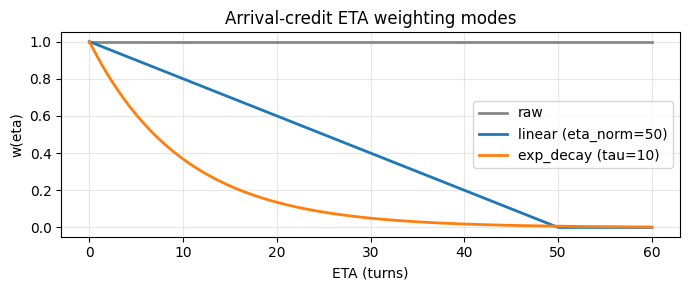

In [ ]:
from rl.arrival_credit import eta_weight

etas = np.linspace(0, 60, 200)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(etas, [eta_weight(e, mode='raw') for e in etas],
        label='raw', linewidth=2, color='#888')
ax.plot(etas, [eta_weight(e, mode='linear', eta_norm=50.0) for e in etas],
        label='linear (eta_norm=50)', linewidth=2)
ax.plot(etas, [eta_weight(e, mode='exp_decay', tau=10.0) for e in etas],
        label='exp_decay (tau=10)', linewidth=2)
ax.set_xlabel('ETA (turns)')
ax.set_ylabel('w(eta)')
ax.set_title('Arrival-credit ETA weighting modes')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


### 10.2 Per-planet 12-kanal metric vektörü

`compute_graph_metrics_summary` global SUM döndürdüğü için snapshot için
yetersiz (target-spesifik bilgi yok).  Bu yüzden yeni
`compute_planet_metric_vectors` helper'ı eklendi: PyG kernellerini
çağırıp `(num_real_planets, 12)` per-planet matrisi döner.  Kanal
sırası `graph_native` reward'ın 12-vektörüyle birebir aynı.

Per-planet metric matrix shape: (36, 12)
Channel labels (12):
  fr_influence, en_influence, inf_balance, fr_support, supportability, vulnerability, prod_potential, strategic_potential, flux_fr_in, flux_fr_out, flux_en_in, flux_en_out


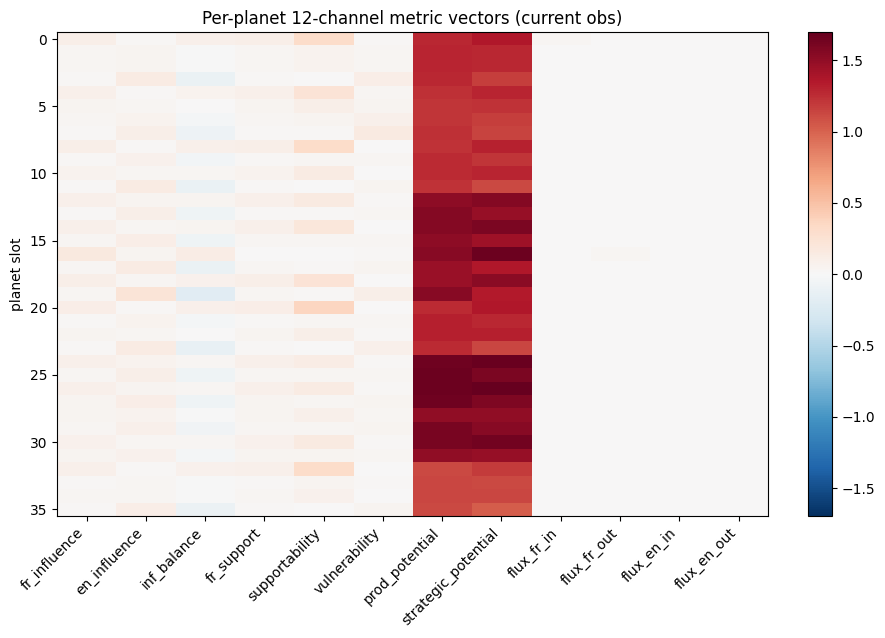

In [ ]:
from rl.rewards import compute_planet_metric_vectors, build_reward_config

cfg_b = build_reward_config('graph_native', enable_flux_metrics=True)
mat = compute_planet_metric_vectors(obs, cfg=cfg_b)
print('Per-planet metric matrix shape:', mat.shape)
print('Channel labels (12):')
labels = [
    'fr_influence', 'en_influence', 'inf_balance',
    'fr_support', 'supportability', 'vulnerability',
    'prod_potential', 'strategic_potential',
    'flux_fr_in', 'flux_fr_out', 'flux_en_in', 'flux_en_out',
]
print('  ' + ', '.join(labels))

fig, ax = plt.subplots(figsize=(9, max(3, 0.18 * mat.shape[0])))
im = ax.imshow(mat, aspect='auto', cmap='RdBu_r',
               vmin=-np.max(np.abs(mat)), vmax=np.max(np.abs(mat)))
ax.set_xticks(range(12))
ax.set_xticklabels(labels, rotation=45, ha='right')
ax.set_ylabel('planet slot')
ax.set_title('Per-planet 12-channel metric vectors (current obs)')
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()


### 10.3 `ArrivalCreditTracker` — register → compute_credit

Tracker iki ana fonksiyon sunuyor:

- `register(buffer_idx, player, target_planet_id, eta_at_launch,
   launch_metric_matrix, launch_planet_ids, ...)` — launch anında
  snapshot al.
- `compute_credit(buffer_idx, curr_metric_matrix, curr_planet_ids,
   channel_weights, cfg)` — arrival anında farkı hesapla, snapshot'ı
  consume et, kredi döndür.

Ayrıca iki diagnostic counter var: `credits_emitted` (kaç arrival
çözüldü) ve `credits_total` (signed running sum).  Training-time
log'a verilecek.

In [ ]:
from rl.arrival_credit import ArrivalCreditTracker, build_channel_weights

# Mini sandbox: 2 planet, 12 kanal hepsi sıfır.
ids = np.array([100, 101], dtype=np.int32)
launch_mat = np.zeros((2, 12), dtype=np.float32)

tr = ArrivalCreditTracker()
tr.register(
    buffer_idx=0, player=0,
    target_planet_id=100,
    eta_at_launch=8.0,
    launch_metric_matrix=launch_mat,
    launch_planet_ids=ids,
)
print('Snapshot kayıtlı:', 0 in tr, '|', 'pending =', len(tr))

# Arrival turn'ünde target planet'in 0. kanalı (friendly_influence) +1.0.
curr_mat = launch_mat.copy()
curr_mat[0, 0] = 1.0
weights = build_channel_weights(cfg_b)  # cfg_b: graph_native preset
print('channel_weights =', weights)

credit = tr.compute_credit(
    buffer_idx=0,
    curr_metric_matrix=curr_mat,
    curr_planet_ids=ids,
    channel_weights=weights,
    cfg=build_reward_config(
        'graph_native',
        enable_arrival_credit=True,
        arrival_credit_mode='exp_decay',
        arrival_credit_tau=10.0,
        arrival_credit_weight=1.0,
    ),
)
print(f'\nCredit @ ETA=8, tau=10 (exp_decay): {credit:.4f}')
print(f'Beklenen ≈ exp(-0.8) * graph_friendly_influence_weight * reward_scale')
print(f'            = exp(-0.8) * 1.0 * 0.001 = {np.exp(-0.8) * 1.0 * 0.001:.4f}')
print(f'\nDiagnostic: credits_emitted={tr.credits_emitted}, '
      f'credits_total={tr.credits_total:.4f}')


Snapshot kayıtlı: True | pending = 1
channel_weights = [ 1. -1.  0.  1.  1. -1.  1.  0.  0.  0.  0.  0.]

Credit @ ETA=8, tau=10 (exp_decay): 0.0004
Beklenen ≈ exp(-0.8) * graph_friendly_influence_weight * reward_scale
            = exp(-0.8) * 1.0 * 0.001 = 0.0004

Diagnostic: credits_emitted=1, credits_total=0.0004


### 10.4 Tüm 12 kanalın katkısı — per-channel ablation

Kullanıcının kritik isteği: **"tüm metriklere etki ettiğine emin
olalım"**.  Her kanala sırayla +1 delta verip credit'i ölçelim;
beklenen davranış: kanal $c$'ye $w_c$ ağırlığı atadıysak credit =
$w_c$ olmalı (ETA=0, raw mod).  Bu invariant
`test_all_twelve_channels_contribute[c]` ile her PR'da otomatik test
ediliyor.

/tmp/ipykernel_755622/399292643.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=40, ha='right')


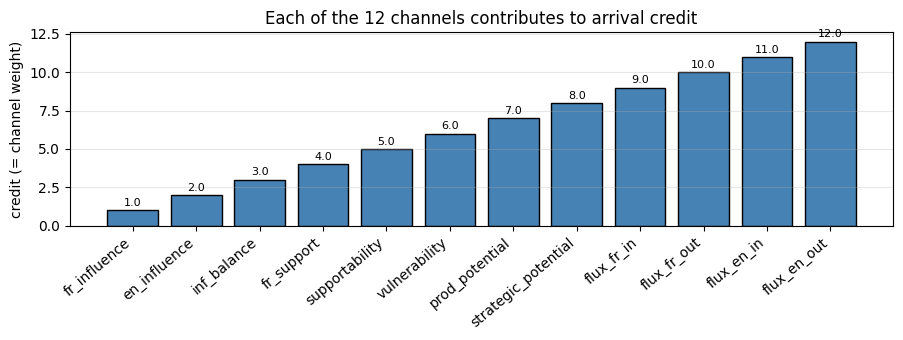

Beklenen: [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0]
Ölçülen : [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0]
✓ Hepsi kanal ağırlığına eşit — TÜM 12 kanal etkili.


In [ ]:
# Ablation: her kanalı tek başına +1 vur, credit'i ölç.
labels = [
    'fr_influence', 'en_influence', 'inf_balance',
    'fr_support', 'supportability', 'vulnerability',
    'prod_potential', 'strategic_potential',
    'flux_fr_in', 'flux_fr_out', 'flux_en_in', 'flux_en_out',
]

# Her kanal için ayrı, ağırlık = kanal index + 1 (ölçek görünür olsun).
weights_per_channel = np.arange(1, 13, dtype=np.float32)
credits = []
for c in range(12):
    tr = ArrivalCreditTracker()
    launch_mat = np.zeros((2, 12), dtype=np.float32)
    tr.register(
        buffer_idx=0, player=0,
        target_planet_id=100, eta_at_launch=0.0,
        launch_metric_matrix=launch_mat, launch_planet_ids=ids,
    )
    curr_mat = launch_mat.copy()
    curr_mat[0, c] = 1.0
    w = np.zeros(12, dtype=np.float32)
    w[c] = weights_per_channel[c]
    credit = tr.compute_credit(
        buffer_idx=0,
        curr_metric_matrix=curr_mat, curr_planet_ids=ids,
        channel_weights=w,
        cfg=build_reward_config('graph_native', enable_arrival_credit=True,
                                arrival_credit_mode='raw',
                                arrival_credit_weight=1.0,
                                reward_scale=1.0),
    )
    credits.append(credit)

fig, ax = plt.subplots(figsize=(9, 3.5))
bars = ax.bar(labels, credits, color='steelblue', edgecolor='black')
for b, c, w in zip(bars, credits, weights_per_channel):
    ax.annotate(f'{c:.1f}', xy=(b.get_x() + b.get_width()/2, c),
                xytext=(0, 3), textcoords='offset points',
                ha='center', fontsize=8)
ax.set_xticklabels(labels, rotation=40, ha='right')
ax.set_ylabel('credit (= channel weight)')
ax.set_title('Each of the 12 channels contributes to arrival credit')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()
print('Beklenen:', weights_per_channel.tolist())
print('Ölçülen :', [round(c, 4) for c in credits])
assert np.allclose(credits, weights_per_channel, atol=1e-6), (
    'Bir kanal credit\'e katkı vermiyor; refactor regression!')
print('✓ Hepsi kanal ağırlığına eşit — TÜM 12 kanal etkili.')


### 10.5 Rollout entegrasyonu + diagnostic counters

Şimdi kısa bir self-play episode toplayalım ve tracker'ın gerçekten
fire ettiğini gözlemleyelim.  Diagnostic counter'lar training-time
log'a koymak için ideal.

Episode adımı: 56 (P0) + 40 (P1)
register() çağrısı : 65
compute_credit() çağrısı: 21 (21 non-zero)


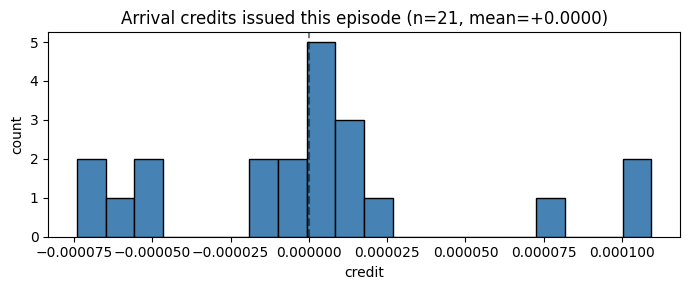

In [ ]:
import torch
from rl import arrival_credit as ac_mod
from rl.buffer import RolloutBuffer
from rl.rollout import collect_episode
from rl.train import _make_policy

# Spy on the tracker class so we can count calls.
register_calls = []
credit_calls = []
orig_register = ac_mod.ArrivalCreditTracker.register
orig_credit = ac_mod.ArrivalCreditTracker.compute_credit

def _spy_register(self, **kwargs):
    register_calls.append(kwargs.get('buffer_idx'))
    return orig_register(self, **kwargs)

def _spy_credit(self, **kwargs):
    res = orig_credit(self, **kwargs)
    credit_calls.append((kwargs.get('buffer_idx'), res))
    return res

ac_mod.ArrivalCreditTracker.register = _spy_register
ac_mod.ArrivalCreditTracker.compute_credit = _spy_credit

torch.manual_seed(0)
policy = _make_policy('pyg_planet_graph', d_model=48, n_layers=1,
                     enable_flux_features=False, enable_sinkhorn=False)
policy.to(torch.device('cpu'))

cfg = build_reward_config(
    'graph_native',
    enable_arrival_credit=True,
    arrival_credit_mode='exp_decay',
    arrival_credit_tau=10.0,
    arrival_credit_weight=1.0,
)
buf = RolloutBuffer()
collect_episode(policy, buf, max_steps=40, num_agents=2,
                reward_cfg=cfg, device=torch.device('cpu'), seed=7)

# Reset class-level patches
ac_mod.ArrivalCreditTracker.register = orig_register
ac_mod.ArrivalCreditTracker.compute_credit = orig_credit

print(f'Episode adımı: {len([tr for tr in buf.data if tr.player==0])} (P0) '
      f'+ {len([tr for tr in buf.data if tr.player==1])} (P1)')
print(f'register() çağrısı : {len(register_calls)}')
print(f'compute_credit() çağrısı: {len(credit_calls)} '
      f'({sum(1 for _,c in credit_calls if c is not None and c!=0)} non-zero)')

# Distribution of credit magnitudes
non_zero_credits = [c for _, c in credit_calls if c is not None and c != 0.0]
if non_zero_credits:
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.hist(non_zero_credits, bins=20, color='steelblue', edgecolor='black')
    ax.axvline(0, color='k', linestyle='--', alpha=0.5)
    ax.set_xlabel('credit')
    ax.set_ylabel('count')
    ax.set_title(f'Arrival credits issued this episode '
                 f'(n={len(non_zero_credits)}, '
                 f'mean={np.mean(non_zero_credits):+.4f})')
    plt.tight_layout(); plt.show()
else:
    print('Bu episode\'de henüz arrival olmadı (kısa episode).')


### 10.6 CLI — arrival-credit ile eğitim

Mevcut graph-native + flux pipeline'ının üstüne arrival-credit eklemek
sadece bir flag:

```bash
python -m rl.train \
  --model-variant pyg_planet_graph \
  --reward-system graph_native --opponent scripted \
  --enable-flux-metrics --enable-arrival-credit \
  --arrival-credit-mode exp_decay --arrival-credit-tau 10.0 \
  --arrival-credit-weight 0.5 \
  --iterations 200 --episodes-per-iter 5 --max-episode-steps 500 \
  --d-model 96 --n-layers 2 --device cuda \
  --checkpoint-dir checkpoints/arrival_credit_run \
  --log-path checkpoints/arrival_credit_run/log.jsonl
```

**Ablation önerisi**:

| Run | Flux pot. shaping | Arrival credit | Beklenen |
|-----|---|---|---|
| A | ✓ | ✗ | Baseline (mevcut) |
| B | ✗ | ✓ | Arrival sinyalinin tek başına gücü |
| C | ✓ | ✓ (α=0.5) | İki sinyal birlikte; valL varyansını izle |
| D | ✓ | ✓ (`--arrival-credit-include-source`) | Trade-off encoded |

Detaylı tasarım: [`docs/arrival_credit_design.md`](arrival_credit_design.md).